In [1]:
# ============================================================
# Stage 05 - Model Evaluation
# Step 5.1 - Setup & Load Saved Models
# ============================================================

from pathlib import Path
import json
import joblib
import pandas as pd
import numpy as np
import torch

from sentence_transformers import SentenceTransformer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Locate project directory
CURRENT_DIR = Path.cwd().resolve()

PROJECT_DIR = next(
    (
        p for p in [CURRENT_DIR, *CURRENT_DIR.parents]
        if (p / "data" / "processed" / "test.csv").exists()
    ),
    None
)

assert PROJECT_DIR is not None, "Project directory not found!"

# 2. Define paths
DATA_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 3. Load held-out test dataset
test_df = pd.read_csv(
    DATA_DIR / "test.csv",
    dtype=str,
    keep_default_na=False
)

X_test = test_df["text"]
y_test = test_df["label"]

# 4. Load traditional model
traditional_model = joblib.load(
    MODEL_DIR / "traditional_tfidf_logreg.joblib"
)

# 5. Load MiniLM encoder and classifier
MINILM_DIR = MODEL_DIR / "minilm"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

minilm_encoder = SentenceTransformer(
    str(MINILM_DIR / "sentence_transformer"),
    device=DEVICE
)

minilm_classifier = joblib.load(
    MINILM_DIR / "classifier.joblib"
)

# 6. Load MiniLM configuration
with open(
    MINILM_DIR / "config.json",
    "r",
    encoding="utf-8"
) as f:
    minilm_config = json.load(f)

# 7. Verify compatibility
assert len(test_df) == 763
assert X_test.str.strip().ne("").all()

assert set(y_test.unique()) == set(
    traditional_model.classes_
)

assert set(y_test.unique()) == set(
    minilm_classifier.classes_
)

assert minilm_config["normalize_embeddings"] is True

assert (
    minilm_encoder.get_sentence_embedding_dimension()
    == 384
)

# ============================================================
# Results
# ============================================================

print("=" * 55)
print("STAGE 05 - MODEL EVALUATION SETUP")
print("=" * 55)

print("Test Examples:", len(X_test))
print("Number of Classes:", y_test.nunique())

print("\nModels Loaded:")
print("1. TF-IDF + Logistic Regression")
print("2. MiniLM + Logistic Regression")

print("\nMiniLM Device:", DEVICE)
print("MiniLM Dimension:",
      minilm_encoder.get_sentence_embedding_dimension())

print("\nTest Class Distribution:")
print(y_test.value_counts())

print("\nModel Loading Verification: PASSED!")


W1118 02:57:22.134000 27804 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

STAGE 05 - MODEL EVALUATION SETUP
Test Examples: 763
Number of Classes: 5

Models Loaded:
1. TF-IDF + Logistic Regression
2. MiniLM + Logistic Regression

MiniLM Device: cpu
MiniLM Dimension: 384

Test Class Distribution:
label
Electrical System    284
Service Brakes       147
Air Bags             118
Fuel System          111
Steering             103
Name: count, dtype: int64

Model Loading Verification: PASSED!


C:\Users\faisa\AppData\Local\Temp\ipykernel_27804\2108403908.py:93: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  minilm_encoder.get_sentence_embedding_dimension()
C:\Users\faisa\AppData\Local\Temp\ipykernel_27804\2108403908.py:114: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  minilm_encoder.get_sentence_embedding_dimension())


In [2]:
# ============================================================
# Step 5.2 - Final Test Evaluation
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

print("=" * 55)
print("FINAL TEST EVALUATION")
print("=" * 55)

# ============================================================
# Model 1: TF-IDF + Logistic Regression
# ============================================================

print("\nEvaluating Traditional Model...")

traditional_predictions = traditional_model.predict(
    X_test
)

traditional_accuracy = accuracy_score(
    y_test,
    traditional_predictions
)

traditional_macro_f1 = f1_score(
    y_test,
    traditional_predictions,
    average="macro"
)

print("Traditional Model Evaluation Completed!")

# ============================================================
# Model 2: MiniLM + Logistic Regression
# ============================================================

print("\nGenerating Test Embeddings...")

X_test_embeddings = minilm_encoder.encode(
    X_test.tolist(),
    batch_size=minilm_config["batch_size"],
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=minilm_config[
        "normalize_embeddings"
    ]
)

# Verify embedding shape
assert X_test_embeddings.shape == (763, 384)
assert np.isfinite(X_test_embeddings).all()

print("\nEvaluating MiniLM Model...")

minilm_predictions = minilm_classifier.predict(
    X_test_embeddings
)

minilm_accuracy = accuracy_score(
    y_test,
    minilm_predictions
)

minilm_macro_f1 = f1_score(
    y_test,
    minilm_predictions,
    average="macro"
)

print("MiniLM Model Evaluation Completed!")

# ============================================================
# Results Comparison
# ============================================================

comparison_df = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": traditional_accuracy,
        "Macro F1": traditional_macro_f1
    },
    {
        "Model": "MiniLM + Logistic Regression",
        "Accuracy": minilm_accuracy,
        "Macro F1": minilm_macro_f1
    }
])

print("\n" + "=" * 55)
print("FINAL TEST RESULTS")
print("=" * 55)

display(comparison_df.round(4))

# ============================================================
# Count Correct and Incorrect Predictions
# ============================================================

print("\n" + "=" * 55)
print("PREDICTION ANALYSIS")
print("=" * 55)

for name, predictions in [
    ("Traditional", traditional_predictions),
    ("MiniLM", minilm_predictions)
]:

    correct = int(np.sum(
        np.asarray(y_test) == predictions
    ))

    incorrect = len(y_test) - correct

    print(f"\n{name} Model")
    print("Correct Predictions:", correct)
    print("Incorrect Predictions:", incorrect)

# ============================================================
# Verification
# ============================================================

assert len(traditional_predictions) == len(y_test)
assert len(minilm_predictions) == len(y_test)

print("\nFinal Test Evaluation: PASSED!")


FINAL TEST EVALUATION

Evaluating Traditional Model...
Traditional Model Evaluation Completed!

Generating Test Embeddings...


Batches:   0%|          | 0/24 [00:00<?, ?it/s]


Evaluating MiniLM Model...
MiniLM Model Evaluation Completed!

FINAL TEST RESULTS


,Model,Accuracy,Macro F1
0,TF-IDF + Logistic Regression,0.9685,0.9708
1,MiniLM + Logistic Regression,0.9423,0.9458



PREDICTION ANALYSIS

Traditional Model
Correct Predictions: 739
Incorrect Predictions: 24

MiniLM Model
Correct Predictions: 719
Incorrect Predictions: 44

Final Test Evaluation: PASSED!


TRADITIONAL - CLASSIFICATION REPORT
                   precision    recall  f1-score   support

         Air Bags     0.9915    0.9915    0.9915       118
Electrical System     0.9582    0.9683    0.9632       284
      Fuel System     0.9817    0.9640    0.9727       111
   Service Brakes     0.9589    0.9524    0.9556       147
         Steering     0.9709    0.9709    0.9709       103

         accuracy                         0.9685       763
        macro avg     0.9722    0.9694    0.9708       763
     weighted avg     0.9686    0.9685    0.9686       763



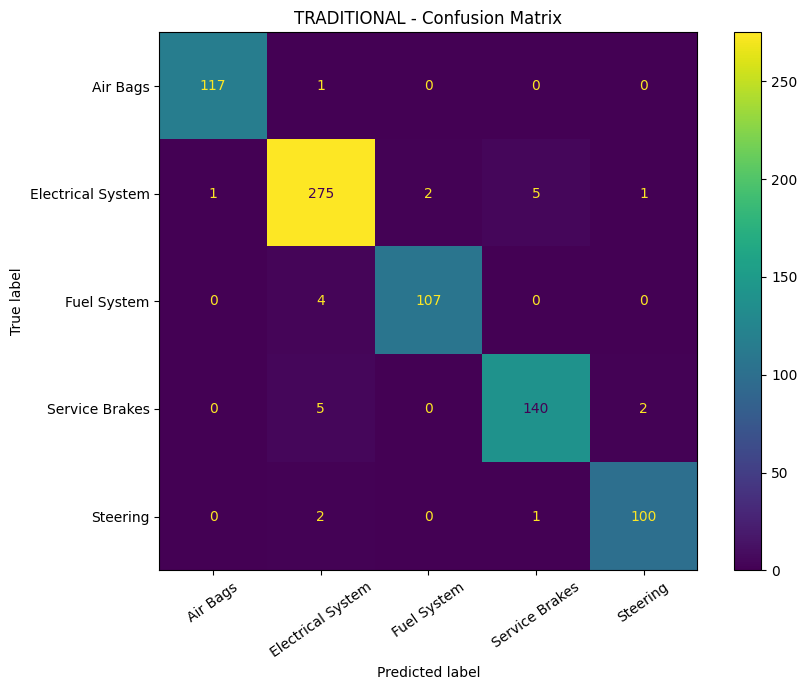

Report Saved: traditional_classification_report.csv
Matrix Saved: traditional_confusion_matrix.png
------------------------------------------------------------
MINILM - CLASSIFICATION REPORT
                   precision    recall  f1-score   support

         Air Bags     0.9658    0.9576    0.9617       118
Electrical System     0.9489    0.9155    0.9319       284
      Fuel System     0.9231    0.9730    0.9474       111
   Service Brakes     0.9211    0.9524    0.9365       147
         Steering     0.9515    0.9515    0.9515       103

         accuracy                         0.9423       763
        macro avg     0.9421    0.9500    0.9458       763
     weighted avg     0.9427    0.9423    0.9423       763



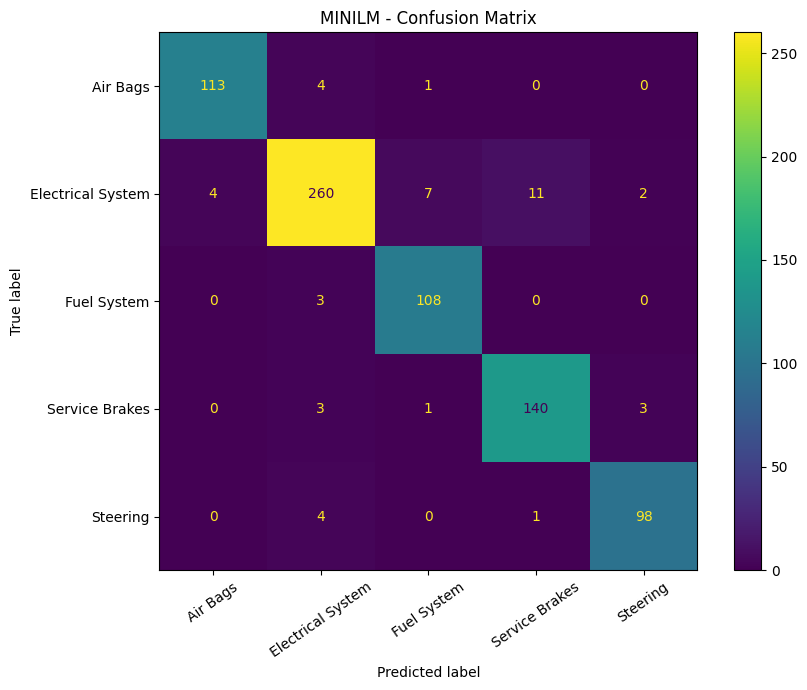

Report Saved: minilm_classification_report.csv
Matrix Saved: minilm_confusion_matrix.png
------------------------------------------------------------

Classification Reports & Matrices: COMPLETED!


In [3]:
# ============================================================
# Step 5.3 - Classification Reports & Confusion Matrices
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create output directory
CM_DIR = RESULTS_DIR / "confusion_matrices"
CM_DIR.mkdir(parents=True, exist_ok=True)

# Consistent class order
CLASS_LABELS = sorted(y_test.unique())

# Models and predictions
models_to_evaluate = {
    "traditional": traditional_predictions,
    "minilm": minilm_predictions
}

for model_name, predictions in models_to_evaluate.items():

    print("=" * 60)
    print(f"{model_name.upper()} - CLASSIFICATION REPORT")
    print("=" * 60)

    # 1. Classification report
    report = classification_report(
        y_test,
        predictions,
        labels=CLASS_LABELS,
        digits=4,
        zero_division=0
    )

    print(report)

    # 2. Save classification report
    report_dict = classification_report(
        y_test,
        predictions,
        labels=CLASS_LABELS,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report_dict).T

    report_path = RESULTS_DIR / (
        f"{model_name}_classification_report.csv"
    )

    report_df.to_csv(
        report_path,
        index=True
    )

    # 3. Generate confusion matrix
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=CLASS_LABELS
    )

    assert cm.sum() == len(y_test)

    # 4. Plot confusion matrix
    fig, ax = plt.subplots(figsize=(9, 7))

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_LABELS
    )

    display_cm.plot(
        ax=ax,
        xticks_rotation=35,
        values_format="d"
    )

    ax.set_title(
        f"{model_name.upper()} - Confusion Matrix"
    )

    plt.tight_layout()

    # 5. Save confusion matrix
    output_path = CM_DIR / (
        f"{model_name}_confusion_matrix.png"
    )

    fig.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Report Saved:", report_path.name)
    print("Matrix Saved:", output_path.name)
    print("-" * 60)

print("\nClassification Reports & Matrices: COMPLETED!")


In [4]:
# ============================================================
# Step 5.4 - Save Final Evaluation Results
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Final metrics
metrics_df = pd.DataFrame([
    {
        "model": "TF-IDF + Logistic Regression",
        "accuracy": accuracy_score(
            y_test, traditional_predictions
        ),
        "macro_f1": f1_score(
            y_test, traditional_predictions,
            average="macro"
        )
    },
    {
        "model": "MiniLM + Logistic Regression",
        "accuracy": accuracy_score(
            y_test, minilm_predictions
        ),
        "macro_f1": f1_score(
            y_test, minilm_predictions,
            average="macro"
        )
    }
])

metrics_df.to_csv(
    RESULTS_DIR / "metrics.csv",
    index=False
)

# 2. Save predictions for Stage 06
predictions_df = test_df[
    ["CAMPNO", "text", "label"]
].copy()

predictions_df = predictions_df.rename(
    columns={"label": "actual_label"}
)

predictions_df["traditional_prediction"] = (
    traditional_predictions
)

predictions_df["minilm_prediction"] = (
    minilm_predictions
)

predictions_df["traditional_correct"] = (
    predictions_df["actual_label"]
    == predictions_df["traditional_prediction"]
)

predictions_df["minilm_correct"] = (
    predictions_df["actual_label"]
    == predictions_df["minilm_prediction"]
)

predictions_df.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False,
    encoding="utf-8"
)

# 3. Save numeric confusion matrices
CM_DIR = RESULTS_DIR / "confusion_matrices"
CM_DIR.mkdir(parents=True, exist_ok=True)

class_labels = sorted(y_test.unique())

for name, predictions in [
    ("traditional", traditional_predictions),
    ("minilm", minilm_predictions)
]:
    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=class_labels
    )

    matrix_df = pd.DataFrame(
        matrix,
        index=class_labels,
        columns=class_labels
    )

    matrix_df.to_csv(
        CM_DIR / f"{name}_confusion_matrix.csv"
    )

# 4. Final verification
assert len(predictions_df) == 763

assert predictions_df["traditional_correct"].sum() == 739
assert predictions_df["minilm_correct"].sum() == 719

assert len(metrics_df) == 2
assert np.isfinite(
    metrics_df[["accuracy", "macro_f1"]].to_numpy()
).all()

print("=" * 55)
print("FINAL EVALUATION FILES")
print("=" * 55)

print("\nFinal Metrics:")
display(metrics_df.round(4))

print("\nPrediction Verification:")
print(
    "Traditional Correct:",
    predictions_df["traditional_correct"].sum()
)
print(
    "MiniLM Correct:",
    predictions_df["minilm_correct"].sum()
)

print("\nSaved Files:")
print("- metrics.csv")
print("- test_predictions.csv")
print("- traditional_confusion_matrix.csv")
print("- minilm_confusion_matrix.csv")

print("\nSTAGE 05 COMPLETED SUCCESSFULLY!")


FINAL EVALUATION FILES

Final Metrics:


,model,accuracy,macro_f1
0,TF-IDF + Logistic Regression,0.9685,0.9708
1,MiniLM + Logistic Regression,0.9423,0.9458



Prediction Verification:
Traditional Correct: 739
MiniLM Correct: 719

Saved Files:
- metrics.csv
- test_predictions.csv
- traditional_confusion_matrix.csv
- minilm_confusion_matrix.csv

STAGE 05 COMPLETED SUCCESSFULLY!
